In [37]:
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor



In [38]:
warnings.filterwarnings("ignore")
print("2. RUNNING CASE 2 REGRESSION & EVALUATION")

2. RUNNING CASE 2 REGRESSION & EVALUATION


# --------------------------------------------------
# 1. LOAD PREPROCESSED REGRESSION DATA
# --------------------------------------------------

In [39]:
# 1. LOAD PREPROCESSED REGRESSION DATA
# --------------------------------------------------

if not os.path.exists("processed_regression/X_train.csv"):
    raise FileNotFoundError(
        "Processed data not found! Run preprocessing_regression.py first."    )

X_train = pd.read_csv("processed_regression/X_train.csv")
X_test = pd.read_csv("processed_regression/X_test.csv")

y_train_log = pd.read_csv("processed_regression/y_train.csv").values.ravel()

y_test_log = pd.read_csv("processed_regression/y_test.csv").values.ravel()

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train_log.shape)
print("y_test shape:", y_test_log.shape)

X_train shape: (108967, 22)
X_test shape: (27242, 22)
y_train shape: (108967,)
y_test shape: (27242,)


In [40]:
# Convert target back from log scale to original km scale
y_test_actual = np.expm1(y_test_log)

In [41]:
# 2. CREATE REGRESSION MODELS
# --------------------------------------------------

models = {

    "Linear Regression": LinearRegression(),

    "Random Forest Regressor": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=1 ),

    "XGBoost Regressor": XGBRegressor(
        n_estimators=100,
        learning_rate=0.1,
        random_state=42,
        n_jobs=1 )}

# ============================================================
# 3. TRAIN AND EVALUATE
# ============================================================


Training Linear Regression...

Training Random Forest Regressor...

Training XGBoost Regressor...

[SUCCESS] Graph saved successfully.


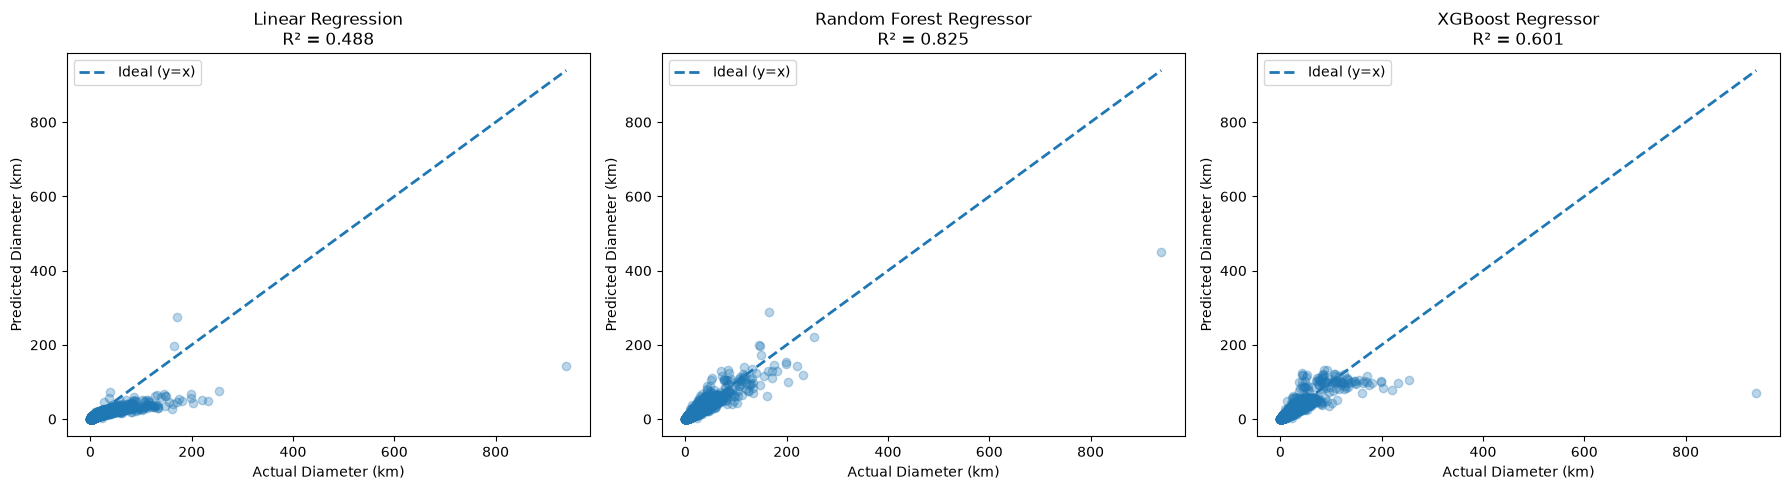

In [44]:
# 3. TRAIN AND EVALUATE
# ============================================================

results_list = []

fig, axes = plt.subplots(1,3,figsize=(18, 5))


for idx, (name, model) in enumerate(models.items()):

    print(f"\nTraining {name}...")

    # Train
    model.fit(X_train,y_train_log )

    # Predict
    y_pred_log = model.predict(X_test)

    # Convert prediction back to km
    y_pred_km = np.expm1(y_pred_log)

    # Avoid negative diameter
    y_pred_km = np.maximum(y_pred_km, 0  )


    # ========================================================
    # Metrics
    # ========================================================

    rmse = np.sqrt( mean_squared_error(y_test_actual, y_pred_km ))

    mae = mean_absolute_error(y_test_actual, y_pred_km)

    r2 = r2_score(y_test_actual, y_pred_km)


    results_list.append({
        "Model": name,
        "RMSE (km)": round(rmse, 4),
        "MAE (km)": round(mae, 4),
        "R2 Score": round(r2, 4)  })


    # ========================================================
    # Graph
    # ========================================================

    axes[idx].scatter(y_test_actual, y_pred_km,alpha=0.3 )

    # Ideal prediction line
    max_val = max(y_test_actual.max(), y_pred_km.max() )

    axes[idx].plot(
        [0, max_val],
        [0, max_val],
        linestyle="--",
        linewidth=2,
        label="Ideal (y=x)" )

    axes[idx].set_title( f"{name}\nR² = {r2:.3f}" )

    axes[idx].set_xlabel("Actual Diameter (km)" )

    axes[idx].set_ylabel("Predicted Diameter (km)" )

    axes[idx].legend()


# ============================================================
# 4. SHOW GRAPH
# ============================================================

plt.tight_layout()

os.makedirs("results", exist_ok=True)

plt.savefig(
    "results/case2_regression_plots.png",
    dpi=300,
    bbox_inches="tight")

print("\n[SUCCESS] Graph saved successfully.")
plt.show()

In [45]:
# 5. RESULTS TABLE
# --------------------------------------------------

results_df = pd.DataFrame(results_list)

results_df = results_df.sort_values(
    by="R2 Score",
    ascending=False)

print("\n==========================================")
print("CASE 2 REGRESSION PERFORMANCE METRICS")
print("==========================================")

print(results_df.to_string(index=False))



CASE 2 REGRESSION PERFORMANCE METRICS
                  Model  RMSE (km)  MAE (km)  R2 Score
Random Forest Regressor     4.1981    1.0389    0.8253
      XGBoost Regressor     6.3421    1.1142    0.6013
      Linear Regression     7.1897    1.5310    0.4876


In [ ]:
# 6. SAVE RESULTS
# --------------------------------------------------

results_df.to_csv("results/case2_regression_results.csv", index=False)

print("\n[SUCCESS] Results saved to "
    "'results/case2_regression_results.csv'")


[SUCCESS] Results saved to 'results/case2_regression_results.csv'
